# EMNIST Balanced: CNN Architecture Experiments

**Goal:** reproduce the CNN experiments in the same order, starting from a simple CNN and changing one main design choice at a time.

- Dataset: EMNIST Balanced (47 classes, 28×28 grayscale images)
- Framework: PyTorch
- Baseline normalization: `ToTensor()` and `Normalize((0.5,), (0.5,))`
- Training batch size: 64
- Default optimizer: Adam, learning rate 0.001
- Main comparison budget: the epoch count used in each experiment below
- Test set: used for comparison as in the original experiments. For a publication-quality final result, keep a separate validation set for model selection and evaluate the test set only once at the end.

**Important:** run the notebook from top to bottom. Training all experiments takes time. Each experiment has its own cell so you can stop, inspect results, and continue. Results can vary slightly because of random initialization, data order, and GPU nondeterminism.

## Experiment history

These are the results previously observed in the original runs. Re-running this notebook may produce slightly different numbers.

| # | Experiment | Best observed test accuracy |
|---:|---|---:|
| 1 | SimpleCNN | 83.14% |
| 2 | TwoLayerCNN | 85.04% |
| 3 | TwoLayerCNN_8 | 83.56% |
| 4 | TwoLayerCNN_Padding | 84.60% |
| 5 | TwoLayerCNN_MaxPool | 85.77% |
| 6 | TwoLayerCNN_16_32 | 86.53% |
| 7 | ThreeLayerCNN (pool after first and second conv) | 85.16% |
| 8 | ThreeLayerCNN_NoSecondPool | 86.73% |
| 9 | ThreeLayerCNN_16_32 | 87.09% |
| 10 | ThreeLayerCNN_BN | 87.61% |
| 11 | ThreeLayerCNN_BN_Dropout (dropout 0.3) | 88.38% |
| 12 | Same architecture, learning rate 0.0005 | 88.27% |
| 13 | Dropout 0.5, fresh 10-epoch run | 88.54% |
| 14 | Dropout 0.5, fresh 20-epoch run | 88.96% |
| 15 | Final channels increased to 64 | 88.74% |
| 16 | Strong random affine augmentation | 88.52% |
| 17 | Mild random affine augmentation | 89.00% |
| 18 | Mild augmentation + ReduceLROnPlateau | 89.14% |
| 19 | Global Average Pooling (GAP) classifier | 82.93% |
| 20 | CNN_BlockModel (two convs per block) | **89.85%** |

Some rows are training-setting variants of an existing architecture, not entirely new architectures. That is why there are 20 experiments even though the number of distinct architecture ideas is smaller.

## 1. Imports and device

In [2]:
import copy
import random
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision.datasets import EMNIST
from torchvision import transforms

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
PyTorch: 2.14.1+cu126


## 2. Dataset and preprocessing

In [3]:
transform_basic = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

transform_mild_train = transforms.Compose([
    transforms.RandomAffine(
        degrees=5,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

transform_strong_train = transforms.Compose([
    transforms.RandomAffine(
        degrees=10,
        translate=(0.1, 0.1),
        scale=(0.9, 1.1)
    ),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

def make_loaders(train_transform, batch_size=64):
    train_dataset = EMNIST(
        root="./data",
        split="balanced",
        train=True,
        download=True,
        transform=train_transform
    )
    test_dataset = EMNIST(
        root="./data",
        split="balanced",
        train=False,
        download=True,
        transform=transform_test
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )
    return train_dataset, test_dataset, train_loader, test_loader

train_dataset, test_dataset, train_loader, test_loader = make_loaders(transform_basic)

classes = train_dataset.classes
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", len(classes))

Training images: 112800
Test images: 18800
Classes: 47


## 3. Inspect a batch

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


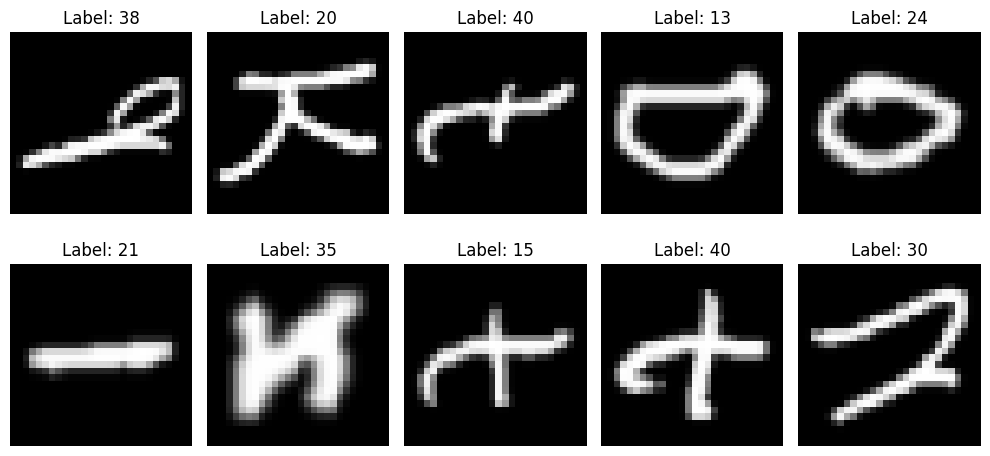

In [4]:
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, image, label in zip(axes.flat, images[:10], labels[:10]):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label.item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Shared training, evaluation, and plotting functions

The model returns raw logits. Do **not** add Softmax before `CrossEntropyLoss`; the loss function handles the required log-softmax operation internally.

For continuity with the original experiments, loss is averaged across batches, and accuracy is calculated across all examples.

In [5]:
def train_step(model, criterion, optimizer, dataloader, device=device):
    running_loss = 0.0
    correct = 0
    model.train()

    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        pred = model(x)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        correct += (pred.argmax(1) == y).float().sum().item()

    return running_loss / len(dataloader), 100 * correct / len(dataloader.dataset)


def test_step(model, criterion, dataloader, device=device):
    running_loss = 0.0
    correct = 0
    model.eval()

    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            running_loss += criterion(pred, y).item()
            correct += (pred.argmax(1) == y).float().sum().item()

    return running_loss / len(dataloader), 100 * correct / len(dataloader.dataset)


experiment_results = []
best_overall = {"accuracy": -1, "experiment": None, "model_state": None}


def run_experiment(name, model, epochs=10, lr=0.001, scheduler_type=None,
                   scheduler_patience=2, scheduler_factor=0.5):
    global best_overall

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    scheduler = None
    if scheduler_type == "plateau":
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=scheduler_factor,
            patience=scheduler_patience
        )

    train_losses, train_accs = [], []
    test_losses, test_accs = [], []
    best_acc = -1.0
    best_epoch = None
    best_loss = None
    best_state = None
    start = time.time()

    for epoch in range(epochs):
        train_loss, train_acc = train_step(model, criterion, optimizer, train_loader)
        test_loss, test_acc = test_step(model, criterion, test_loader)

        if scheduler is not None:
            scheduler.step(test_loss)

        current_lr = optimizer.param_groups[0]["lr"]
        train_losses.append(train_loss)
        train_accs.append(train_acc)
        test_losses.append(test_loss)
        test_accs.append(test_acc)

        if test_acc > best_acc:
            best_acc = test_acc
            best_epoch = epoch + 1
            best_loss = test_loss
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train loss: {train_loss:.3f} | Train acc: {train_acc:.2f}% | "
            f"Test loss: {test_loss:.3f} | Test acc: {test_acc:.2f}% | "
            f"LR: {current_lr:g}"
        )

    elapsed = time.time() - start
    result = {
        "experiment": name,
        "epochs": epochs,
        "learning_rate": lr,
        "best_epoch": best_epoch,
        "best_test_accuracy": best_acc,
        "test_loss_at_best_accuracy": best_loss,
        "final_train_accuracy": train_accs[-1],
        "final_test_accuracy": test_accs[-1],
        "final_test_loss": test_losses[-1],
        "seconds": elapsed,
        "train_losses": train_losses,
        "train_accs": train_accs,
        "test_losses": test_losses,
        "test_accs": test_accs,
        "model_state": best_state,
        "model": model
    }
    experiment_results.append(result)

    if best_acc > best_overall["accuracy"]:
        best_overall = {
            "accuracy": best_acc,
            "experiment": name,
            "model_state": copy.deepcopy(best_state)
        }

    print(f"\nBest test accuracy: {best_acc:.2f}% at epoch {best_epoch}")
    print(f"Test loss at that epoch: {best_loss:.3f}")
    print(f"Elapsed time: {elapsed / 60:.1f} minutes")

    epochs_axis = np.arange(1, epochs + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(epochs_axis, train_losses, label="Train")
    axes[0].plot(epochs_axis, test_losses, label="Test")
    axes[0].set_title(f"{name} — Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_xticks(epochs_axis)
    axes[0].legend()

    axes[1].plot(epochs_axis, train_accs, label="Train")
    axes[1].plot(epochs_axis, test_accs, label="Test")
    axes[1].set_title(f"{name} — Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].set_xticks(epochs_axis)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    return result

## 5. Experiment 1 — SimpleCNN

**What changes:** this is the starting point: one convolutional layer, ReLU, flattening, and a linear classifier. No pooling, batch normalization, or dropout. The convolution has no padding, so 28×28 becomes 26×26.

Epoch 01/5 | Train loss: 0.854 | Train acc: 74.79% | Test loss: 0.638 | Test acc: 80.85% | LR: 0.001
Epoch 02/5 | Train loss: 0.535 | Train acc: 82.99% | Test loss: 0.581 | Test acc: 82.00% | LR: 0.001
Epoch 03/5 | Train loss: 0.457 | Train acc: 85.15% | Test loss: 0.583 | Test acc: 81.93% | LR: 0.001
Epoch 04/5 | Train loss: 0.402 | Train acc: 86.47% | Test loss: 0.579 | Test acc: 82.15% | LR: 0.001
Epoch 05/5 | Train loss: 0.356 | Train acc: 87.87% | Test loss: 0.573 | Test acc: 82.68% | LR: 0.001

Best test accuracy: 82.68% at epoch 5
Test loss at that epoch: 0.573
Elapsed time: 2.5 minutes


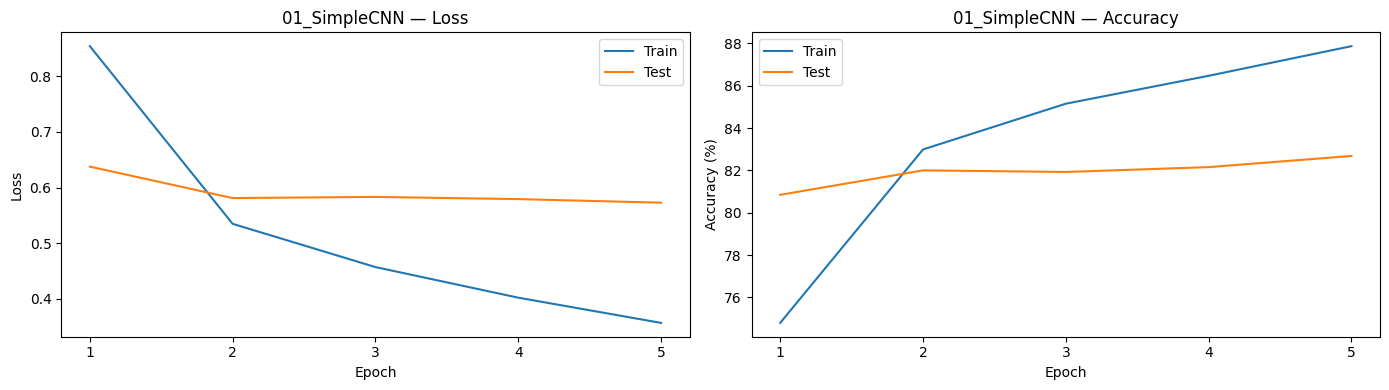

In [6]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(16 * 26 * 26, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_01 = run_experiment("01_SimpleCNN", SimpleCNN(len(classes)), epochs=5, lr=0.001)

## 6. Experiment 2 — TwoLayerCNN

**What changes:** add a second convolution (16→16) before flattening. This tests whether another convolutional feature-extraction step helps. No pooling or padding.

Epoch 01/5 | Train loss: 0.737 | Train acc: 77.64% | Test loss: 0.541 | Test acc: 83.20% | LR: 0.001
Epoch 02/5 | Train loss: 0.458 | Train acc: 85.01% | Test loss: 0.493 | Test acc: 84.57% | LR: 0.001
Epoch 03/5 | Train loss: 0.380 | Train acc: 87.08% | Test loss: 0.484 | Test acc: 84.30% | LR: 0.001
Epoch 04/5 | Train loss: 0.318 | Train acc: 88.78% | Test loss: 0.503 | Test acc: 84.04% | LR: 0.001
Epoch 05/5 | Train loss: 0.265 | Train acc: 90.41% | Test loss: 0.506 | Test acc: 84.09% | LR: 0.001

Best test accuracy: 84.57% at epoch 2
Test loss at that epoch: 0.493
Elapsed time: 2.8 minutes


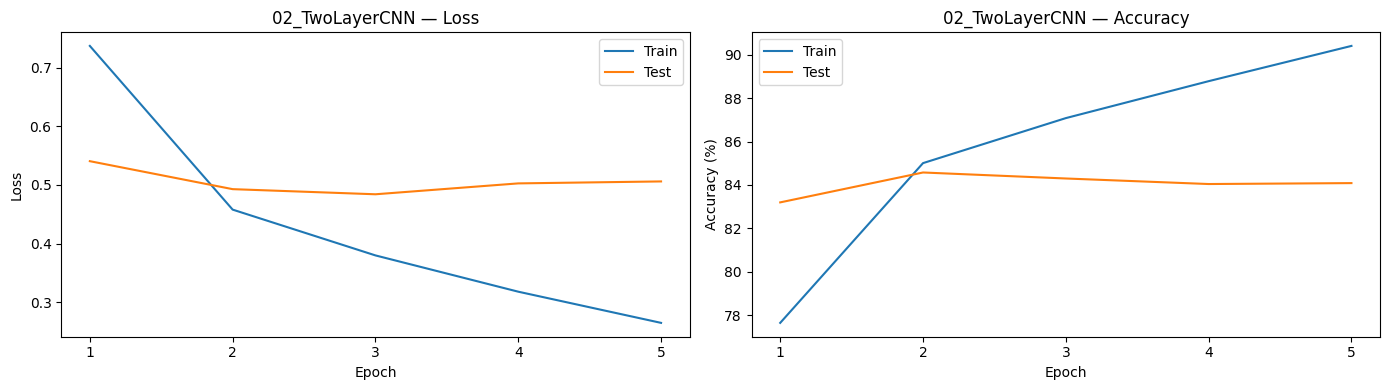

In [7]:
class TwoLayerCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.ReLU(),
            nn.Conv2d(16, 16, 3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(16 * 24 * 24, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_02 = run_experiment("02_TwoLayerCNN", TwoLayerCNN(len(classes)), epochs=5, lr=0.001)

## 7. Experiment 3 — TwoLayerCNN_8

**What changes:** reduce both convolutional layers from 16 channels to 8. This tests whether fewer feature maps can work with fewer parameters.

Epoch 01/5 | Train loss: 0.784 | Train acc: 76.57% | Test loss: 0.579 | Test acc: 82.01% | LR: 0.001
Epoch 02/5 | Train loss: 0.502 | Train acc: 83.77% | Test loss: 0.530 | Test acc: 83.44% | LR: 0.001
Epoch 03/5 | Train loss: 0.434 | Train acc: 85.61% | Test loss: 0.522 | Test acc: 83.77% | LR: 0.001
Epoch 04/5 | Train loss: 0.387 | Train acc: 86.85% | Test loss: 0.511 | Test acc: 83.69% | LR: 0.001
Epoch 05/5 | Train loss: 0.345 | Train acc: 88.04% | Test loss: 0.511 | Test acc: 83.88% | LR: 0.001

Best test accuracy: 83.88% at epoch 5
Test loss at that epoch: 0.511
Elapsed time: 2.9 minutes


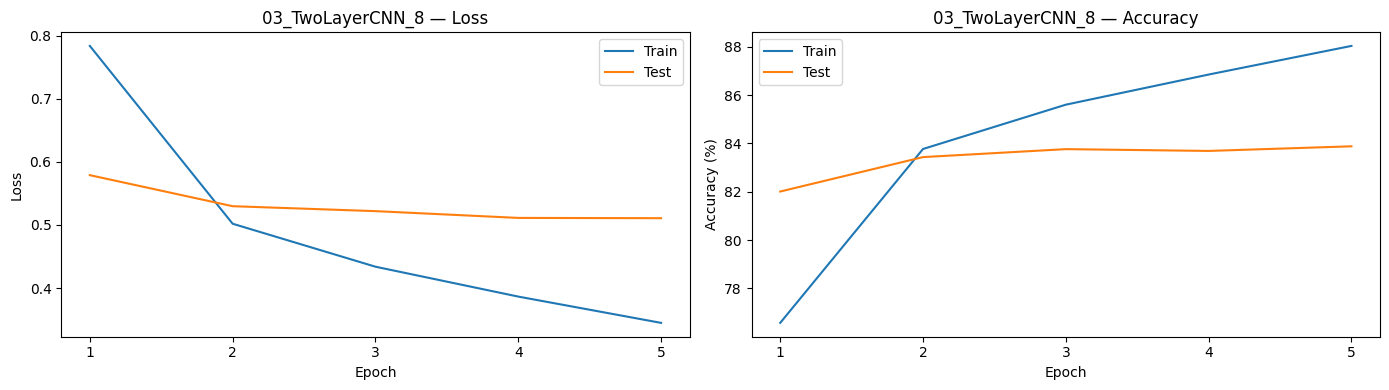

In [8]:
class TwoLayerCNN_8(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 8, 3),
            nn.ReLU(),
            nn.Conv2d(8, 8, 3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(8 * 24 * 24, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_03 = run_experiment("03_TwoLayerCNN_8", TwoLayerCNN_8(len(classes)), epochs=5, lr=0.001)

## 8. Experiment 4 — TwoLayerCNN_Padding

**What changes:** add `padding=1` to both 3×3 convolutions. This preserves the 28×28 spatial size rather than shrinking the image after each convolution. The classifier size changes accordingly.

Epoch 01/5 | Train loss: 0.693 | Train acc: 78.86% | Test loss: 0.534 | Test acc: 82.77% | LR: 0.001
Epoch 02/5 | Train loss: 0.426 | Train acc: 85.80% | Test loss: 0.483 | Test acc: 84.27% | LR: 0.001
Epoch 03/5 | Train loss: 0.356 | Train acc: 87.78% | Test loss: 0.476 | Test acc: 84.89% | LR: 0.001
Epoch 04/5 | Train loss: 0.299 | Train acc: 89.33% | Test loss: 0.497 | Test acc: 84.09% | LR: 0.001
Epoch 05/5 | Train loss: 0.249 | Train acc: 90.93% | Test loss: 0.525 | Test acc: 83.90% | LR: 0.001

Best test accuracy: 84.89% at epoch 3
Test loss at that epoch: 0.476
Elapsed time: 2.5 minutes


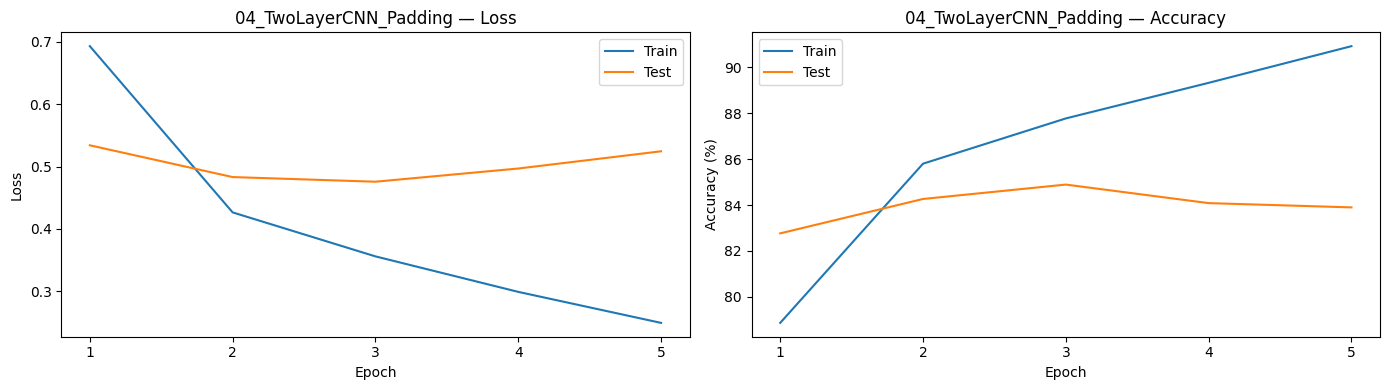

In [9]:
class TwoLayerCNN_Padding(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 16, 3, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(16 * 28 * 28, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_04 = run_experiment("04_TwoLayerCNN_Padding", TwoLayerCNN_Padding(len(classes)), epochs=5, lr=0.001)

## 9. Experiment 5 — TwoLayerCNN_MaxPool

**What changes:** add max pooling after the first convolution. The first feature map is downsampled before the second convolution, reducing the spatial dimensions and classifier size.

Epoch 01/10 | Train loss: 0.706 | Train acc: 78.27% | Test loss: 0.517 | Test acc: 83.23% | LR: 0.001
Epoch 02/10 | Train loss: 0.444 | Train acc: 85.28% | Test loss: 0.471 | Test acc: 84.05% | LR: 0.001
Epoch 03/10 | Train loss: 0.387 | Train acc: 86.66% | Test loss: 0.451 | Test acc: 85.43% | LR: 0.001
Epoch 04/10 | Train loss: 0.349 | Train acc: 87.80% | Test loss: 0.436 | Test acc: 85.41% | LR: 0.001
Epoch 05/10 | Train loss: 0.322 | Train acc: 88.50% | Test loss: 0.430 | Test acc: 85.96% | LR: 0.001
Epoch 06/10 | Train loss: 0.298 | Train acc: 89.18% | Test loss: 0.437 | Test acc: 85.85% | LR: 0.001
Epoch 07/10 | Train loss: 0.278 | Train acc: 89.74% | Test loss: 0.437 | Test acc: 86.33% | LR: 0.001
Epoch 08/10 | Train loss: 0.262 | Train acc: 90.25% | Test loss: 0.446 | Test acc: 85.74% | LR: 0.001
Epoch 09/10 | Train loss: 0.248 | Train acc: 90.65% | Test loss: 0.459 | Test acc: 85.54% | LR: 0.001
Epoch 10/10 | Train loss: 0.234 | Train acc: 91.14% | Test loss: 0.472 | Test acc:

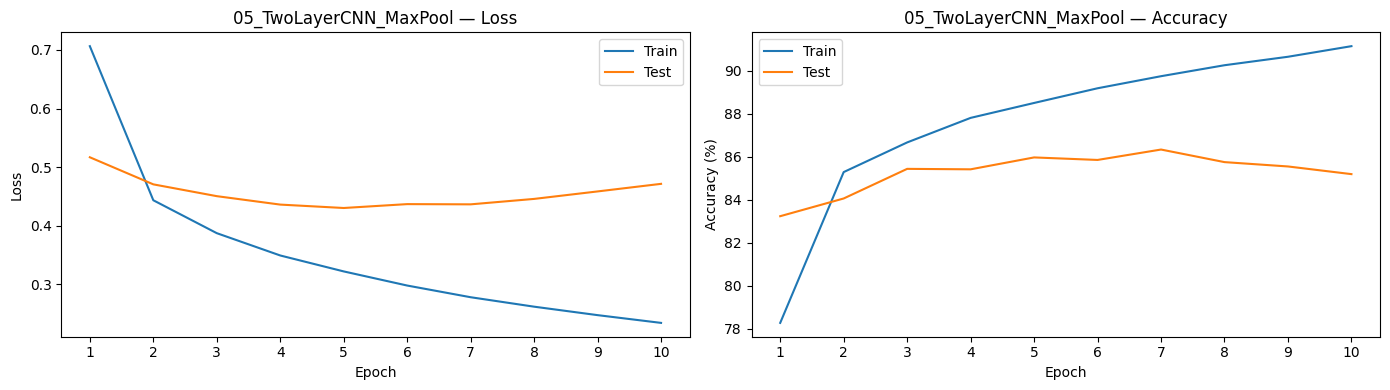

In [10]:
class TwoLayerCNN_MaxPool(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 16, 3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(16 * 11 * 11, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_05 = run_experiment("05_TwoLayerCNN_MaxPool", TwoLayerCNN_MaxPool(len(classes)), epochs=10, lr=0.001)

## 10. Experiment 6 — TwoLayerCNN_16_32

**What changes:** increase the second convolution's channels from 16 to 32. The first layer still has 16 channels, and max pooling remains after the first convolution.

Epoch 01/10 | Train loss: 0.659 | Train acc: 79.67% | Test loss: 0.483 | Test acc: 84.43% | LR: 0.001
Epoch 02/10 | Train loss: 0.407 | Train acc: 86.22% | Test loss: 0.426 | Test acc: 85.89% | LR: 0.001
Epoch 03/10 | Train loss: 0.347 | Train acc: 87.86% | Test loss: 0.415 | Test acc: 86.24% | LR: 0.001
Epoch 04/10 | Train loss: 0.304 | Train acc: 89.08% | Test loss: 0.409 | Test acc: 86.65% | LR: 0.001
Epoch 05/10 | Train loss: 0.271 | Train acc: 90.00% | Test loss: 0.416 | Test acc: 86.07% | LR: 0.001
Epoch 06/10 | Train loss: 0.243 | Train acc: 90.90% | Test loss: 0.434 | Test acc: 86.36% | LR: 0.001
Epoch 07/10 | Train loss: 0.217 | Train acc: 91.66% | Test loss: 0.441 | Test acc: 86.04% | LR: 0.001
Epoch 08/10 | Train loss: 0.198 | Train acc: 92.25% | Test loss: 0.453 | Test acc: 86.15% | LR: 0.001
Epoch 09/10 | Train loss: 0.180 | Train acc: 92.84% | Test loss: 0.499 | Test acc: 85.59% | LR: 0.001
Epoch 10/10 | Train loss: 0.168 | Train acc: 93.26% | Test loss: 0.504 | Test acc:

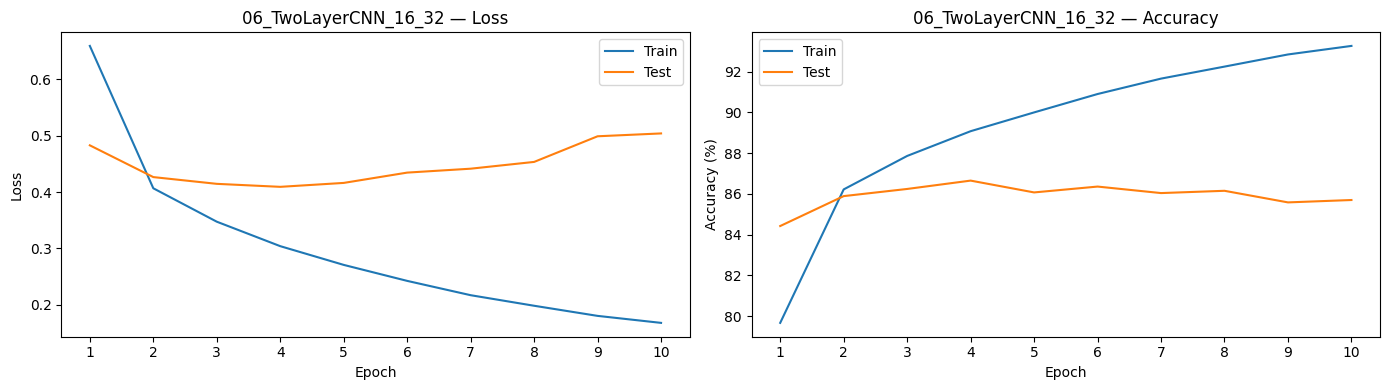

In [11]:
class TwoLayerCNN_16_32(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, 3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * 11 * 11, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_06 = run_experiment("06_TwoLayerCNN_16_32", TwoLayerCNN_16_32(len(classes)), epochs=10, lr=0.001)

## 11. Experiment 7 — ThreeLayerCNN

**What changes:** add a third convolutional layer, keeping 16 channels. Max pooling follows the first and second convolutional layers. This tests a deeper network with more aggressive spatial downsampling.

Epoch 01/10 | Train loss: 1.017 | Train acc: 70.04% | Test loss: 0.629 | Test acc: 80.24% | LR: 0.001
Epoch 02/10 | Train loss: 0.560 | Train acc: 81.68% | Test loss: 0.554 | Test acc: 81.59% | LR: 0.001
Epoch 03/10 | Train loss: 0.495 | Train acc: 83.50% | Test loss: 0.517 | Test acc: 83.23% | LR: 0.001
Epoch 04/10 | Train loss: 0.459 | Train acc: 84.41% | Test loss: 0.471 | Test acc: 84.39% | LR: 0.001
Epoch 05/10 | Train loss: 0.438 | Train acc: 85.04% | Test loss: 0.455 | Test acc: 84.77% | LR: 0.001
Epoch 06/10 | Train loss: 0.421 | Train acc: 85.59% | Test loss: 0.450 | Test acc: 85.29% | LR: 0.001
Epoch 07/10 | Train loss: 0.408 | Train acc: 85.99% | Test loss: 0.440 | Test acc: 84.95% | LR: 0.001
Epoch 08/10 | Train loss: 0.398 | Train acc: 86.18% | Test loss: 0.442 | Test acc: 85.23% | LR: 0.001
Epoch 09/10 | Train loss: 0.391 | Train acc: 86.44% | Test loss: 0.432 | Test acc: 85.19% | LR: 0.001
Epoch 10/10 | Train loss: 0.384 | Train acc: 86.54% | Test loss: 0.421 | Test acc:

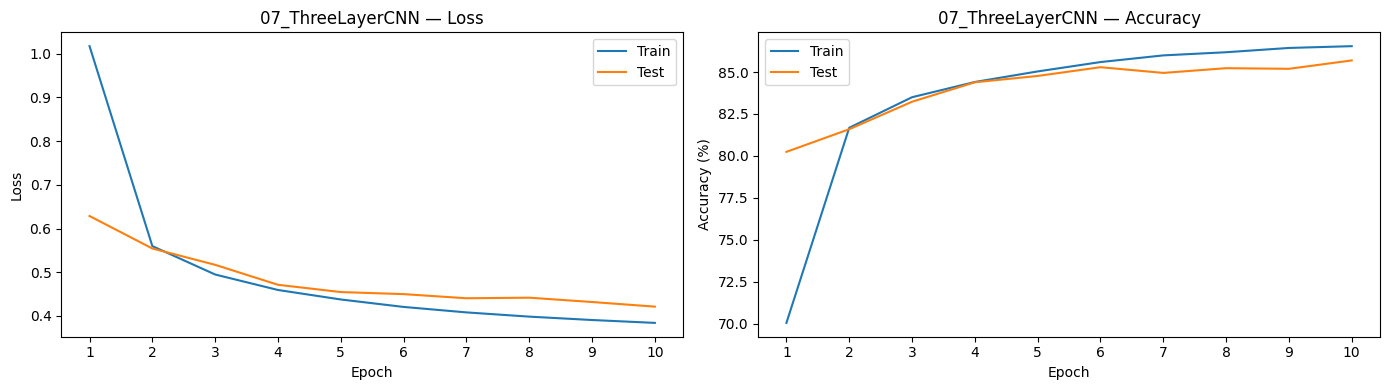

In [12]:
class ThreeLayerCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 16, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 16, 3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(16 * 3 * 3, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_07 = run_experiment("07_ThreeLayerCNN", ThreeLayerCNN(len(classes)), epochs=10, lr=0.001)

## 12. Experiment 8 — ThreeLayerCNN_NoSecondPool

**What changes:** remove the second max-pooling layer. The network still has three 16-channel convolutional layers, but preserves more spatial information for the classifier.

Epoch 01/10 | Train loss: 0.727 | Train acc: 77.77% | Test loss: 0.512 | Test acc: 83.26% | LR: 0.001
Epoch 02/10 | Train loss: 0.435 | Train acc: 85.40% | Test loss: 0.433 | Test acc: 85.77% | LR: 0.001
Epoch 03/10 | Train loss: 0.381 | Train acc: 86.88% | Test loss: 0.417 | Test acc: 86.13% | LR: 0.001
Epoch 04/10 | Train loss: 0.347 | Train acc: 87.80% | Test loss: 0.417 | Test acc: 85.90% | LR: 0.001
Epoch 05/10 | Train loss: 0.323 | Train acc: 88.51% | Test loss: 0.413 | Test acc: 86.17% | LR: 0.001
Epoch 06/10 | Train loss: 0.303 | Train acc: 89.08% | Test loss: 0.400 | Test acc: 86.56% | LR: 0.001
Epoch 07/10 | Train loss: 0.286 | Train acc: 89.43% | Test loss: 0.397 | Test acc: 86.55% | LR: 0.001
Epoch 08/10 | Train loss: 0.272 | Train acc: 89.87% | Test loss: 0.405 | Test acc: 86.76% | LR: 0.001
Epoch 09/10 | Train loss: 0.259 | Train acc: 90.28% | Test loss: 0.411 | Test acc: 86.26% | LR: 0.001
Epoch 10/10 | Train loss: 0.248 | Train acc: 90.54% | Test loss: 0.424 | Test acc:

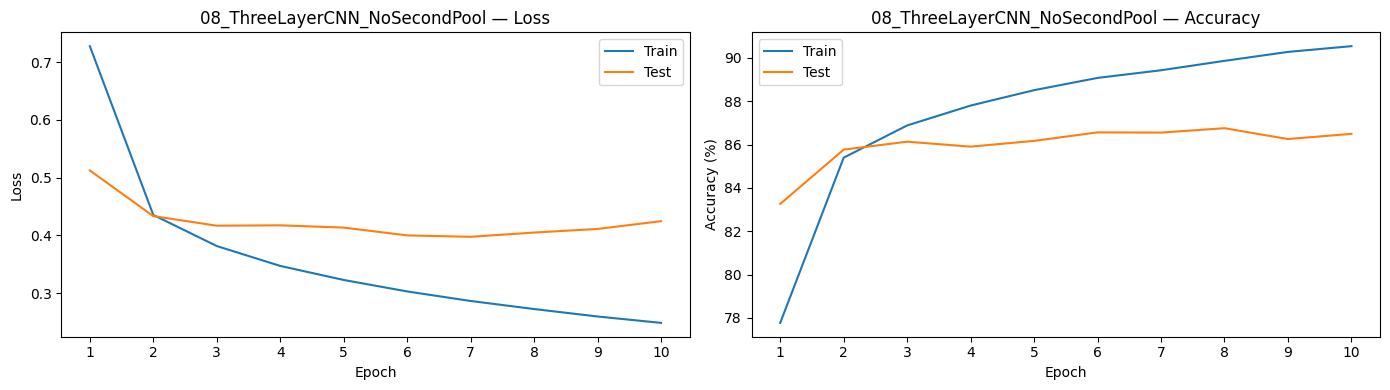

In [13]:
class ThreeLayerCNN_NoSecondPool(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 16, 3),
            nn.ReLU(),
            nn.Conv2d(16, 16, 3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(16 * 9 * 9, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_08 = run_experiment("08_ThreeLayerCNN_NoSecondPool", ThreeLayerCNN_NoSecondPool(len(classes)), epochs=10, lr=0.001)

## 13. Experiment 9 — ThreeLayerCNN_16_32

**What changes:** increase the second and third convolutional layers from 16 to 32 channels. Keep the single max-pooling layer after the first convolution.

Epoch 01/10 | Train loss: 0.666 | Train acc: 79.30% | Test loss: 0.473 | Test acc: 84.18% | LR: 0.001
Epoch 02/10 | Train loss: 0.402 | Train acc: 86.29% | Test loss: 0.423 | Test acc: 85.77% | LR: 0.001
Epoch 03/10 | Train loss: 0.348 | Train acc: 87.63% | Test loss: 0.399 | Test acc: 86.34% | LR: 0.001
Epoch 04/10 | Train loss: 0.314 | Train acc: 88.57% | Test loss: 0.392 | Test acc: 86.98% | LR: 0.001
Epoch 05/10 | Train loss: 0.286 | Train acc: 89.41% | Test loss: 0.378 | Test acc: 87.20% | LR: 0.001
Epoch 06/10 | Train loss: 0.264 | Train acc: 90.07% | Test loss: 0.390 | Test acc: 87.32% | LR: 0.001
Epoch 07/10 | Train loss: 0.246 | Train acc: 90.53% | Test loss: 0.396 | Test acc: 87.26% | LR: 0.001
Epoch 08/10 | Train loss: 0.229 | Train acc: 91.13% | Test loss: 0.422 | Test acc: 86.78% | LR: 0.001
Epoch 09/10 | Train loss: 0.214 | Train acc: 91.60% | Test loss: 0.421 | Test acc: 86.69% | LR: 0.001
Epoch 10/10 | Train loss: 0.201 | Train acc: 92.06% | Test loss: 0.452 | Test acc:

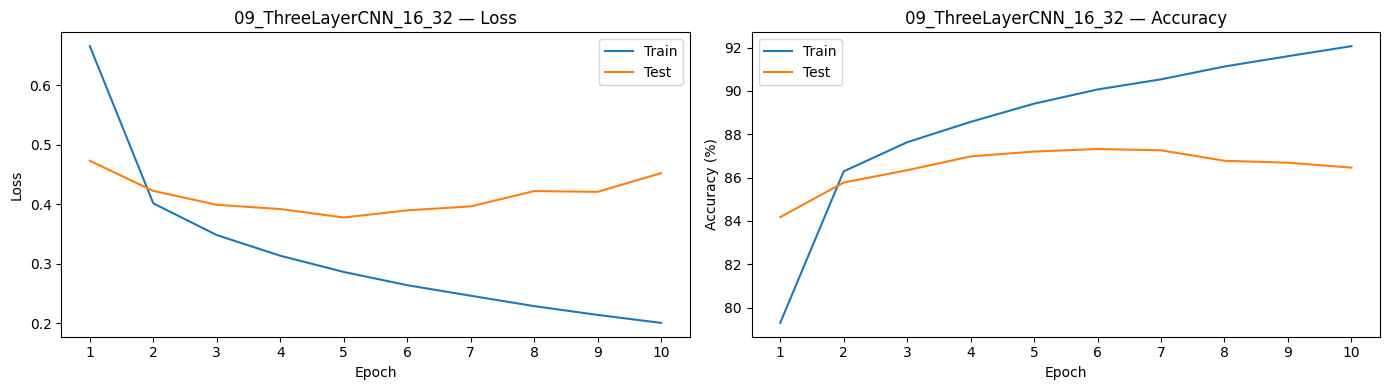

In [14]:
class ThreeLayerCNN_16_32(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, 3),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * 9 * 9, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_09 = run_experiment("09_ThreeLayerCNN_16_32", ThreeLayerCNN_16_32(len(classes)), epochs=10, lr=0.001)

## 14. Experiment 10 — ThreeLayerCNN_BN

**What changes:** add Batch Normalization after each convolution and before ReLU. The convolutional channel sizes and pooling layout remain the same.

Epoch 01/10 | Train loss: 0.558 | Train acc: 82.01% | Test loss: 0.411 | Test acc: 86.26% | LR: 0.001
Epoch 02/10 | Train loss: 0.371 | Train acc: 86.97% | Test loss: 0.384 | Test acc: 87.09% | LR: 0.001
Epoch 03/10 | Train loss: 0.327 | Train acc: 88.28% | Test loss: 0.369 | Test acc: 87.63% | LR: 0.001
Epoch 04/10 | Train loss: 0.295 | Train acc: 89.22% | Test loss: 0.365 | Test acc: 87.60% | LR: 0.001
Epoch 05/10 | Train loss: 0.270 | Train acc: 89.98% | Test loss: 0.356 | Test acc: 87.98% | LR: 0.001
Epoch 06/10 | Train loss: 0.249 | Train acc: 90.70% | Test loss: 0.367 | Test acc: 87.72% | LR: 0.001
Epoch 07/10 | Train loss: 0.228 | Train acc: 91.30% | Test loss: 0.377 | Test acc: 87.30% | LR: 0.001
Epoch 08/10 | Train loss: 0.211 | Train acc: 91.82% | Test loss: 0.383 | Test acc: 87.60% | LR: 0.001
Epoch 09/10 | Train loss: 0.194 | Train acc: 92.43% | Test loss: 0.399 | Test acc: 86.95% | LR: 0.001
Epoch 10/10 | Train loss: 0.181 | Train acc: 92.84% | Test loss: 0.401 | Test acc:

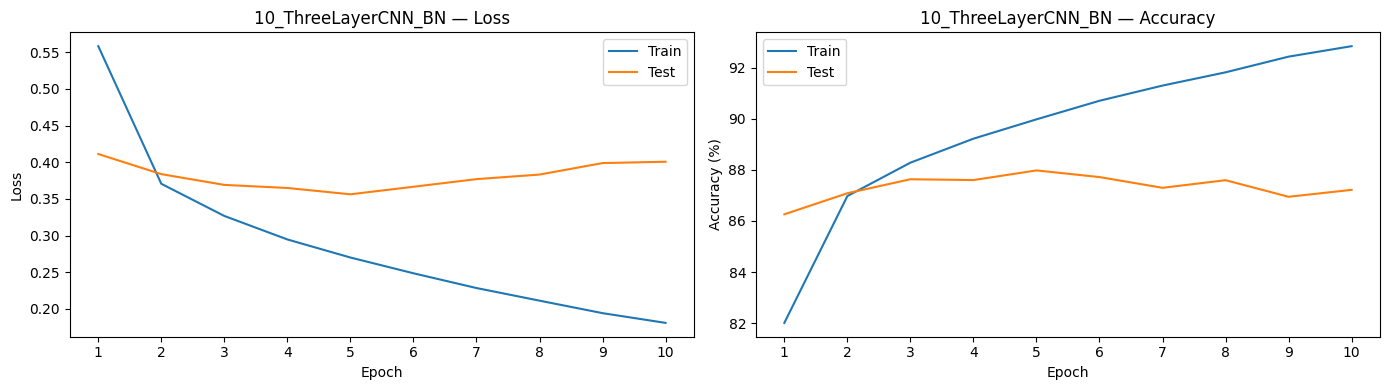

In [15]:
class ThreeLayerCNN_BN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, 3),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, 3),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Flatten(),
            nn.Linear(32 * 9 * 9, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_10 = run_experiment("10_ThreeLayerCNN_BN", ThreeLayerCNN_BN(len(classes)), epochs=10, lr=0.001)

## 15. Experiment 11 — ThreeLayerCNN_BN_Dropout (dropout 0.3)

**What changes:** add Dropout(0.3) immediately before the final linear classifier. Batch Normalization stays in place. This tests regularization of the classifier.

Epoch 01/10 | Train loss: 0.592 | Train acc: 81.10% | Test loss: 0.437 | Test acc: 85.51% | LR: 0.001
Epoch 02/10 | Train loss: 0.394 | Train acc: 86.29% | Test loss: 0.393 | Test acc: 86.52% | LR: 0.001
Epoch 03/10 | Train loss: 0.354 | Train acc: 87.40% | Test loss: 0.369 | Test acc: 87.31% | LR: 0.001
Epoch 04/10 | Train loss: 0.329 | Train acc: 88.14% | Test loss: 0.357 | Test acc: 87.75% | LR: 0.001
Epoch 05/10 | Train loss: 0.310 | Train acc: 88.67% | Test loss: 0.355 | Test acc: 88.21% | LR: 0.001
Epoch 06/10 | Train loss: 0.295 | Train acc: 89.15% | Test loss: 0.353 | Test acc: 87.83% | LR: 0.001
Epoch 07/10 | Train loss: 0.281 | Train acc: 89.55% | Test loss: 0.345 | Test acc: 88.26% | LR: 0.001
Epoch 08/10 | Train loss: 0.270 | Train acc: 89.85% | Test loss: 0.347 | Test acc: 88.03% | LR: 0.001
Epoch 09/10 | Train loss: 0.262 | Train acc: 90.02% | Test loss: 0.347 | Test acc: 88.48% | LR: 0.001
Epoch 10/10 | Train loss: 0.252 | Train acc: 90.48% | Test loss: 0.352 | Test acc:

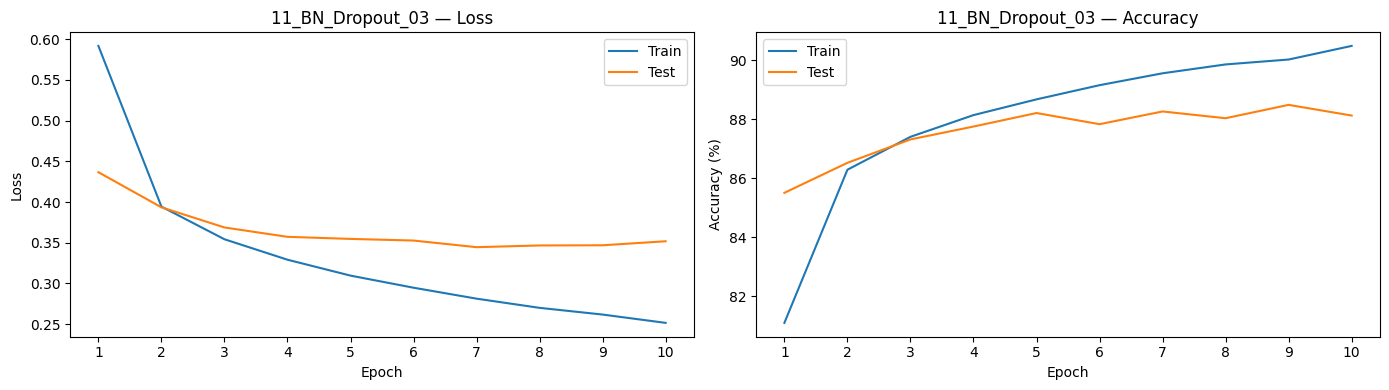

In [16]:
class ThreeLayerCNN_BN_Dropout(nn.Module):
    def __init__(self, num_classes, dropout=0.3, final_channels=32):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, 3),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, final_channels, 3),
            nn.BatchNorm2d(final_channels),
            nn.ReLU(),

            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(final_channels * 9 * 9, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_11 = run_experiment("11_BN_Dropout_03", ThreeLayerCNN_BN_Dropout(len(classes), dropout=0.3), epochs=10, lr=0.001)

## 16. Experiment 12 — Same model, learning rate 0.0005

**What changes:** architecture is unchanged from Experiment 11. Only Adam's learning rate is reduced from 0.001 to 0.0005.

Epoch 01/10 | Train loss: 0.634 | Train acc: 80.21% | Test loss: 0.447 | Test acc: 85.26% | LR: 0.0005
Epoch 02/10 | Train loss: 0.410 | Train acc: 85.97% | Test loss: 0.393 | Test acc: 86.94% | LR: 0.0005
Epoch 03/10 | Train loss: 0.367 | Train acc: 87.16% | Test loss: 0.377 | Test acc: 87.11% | LR: 0.0005
Epoch 04/10 | Train loss: 0.338 | Train acc: 87.96% | Test loss: 0.366 | Test acc: 87.34% | LR: 0.0005
Epoch 05/10 | Train loss: 0.320 | Train acc: 88.38% | Test loss: 0.370 | Test acc: 87.34% | LR: 0.0005
Epoch 06/10 | Train loss: 0.306 | Train acc: 88.87% | Test loss: 0.348 | Test acc: 88.35% | LR: 0.0005
Epoch 07/10 | Train loss: 0.291 | Train acc: 89.30% | Test loss: 0.353 | Test acc: 88.07% | LR: 0.0005
Epoch 08/10 | Train loss: 0.280 | Train acc: 89.65% | Test loss: 0.351 | Test acc: 88.27% | LR: 0.0005
Epoch 09/10 | Train loss: 0.271 | Train acc: 89.90% | Test loss: 0.351 | Test acc: 88.11% | LR: 0.0005
Epoch 10/10 | Train loss: 0.263 | Train acc: 90.13% | Test loss: 0.353 | 

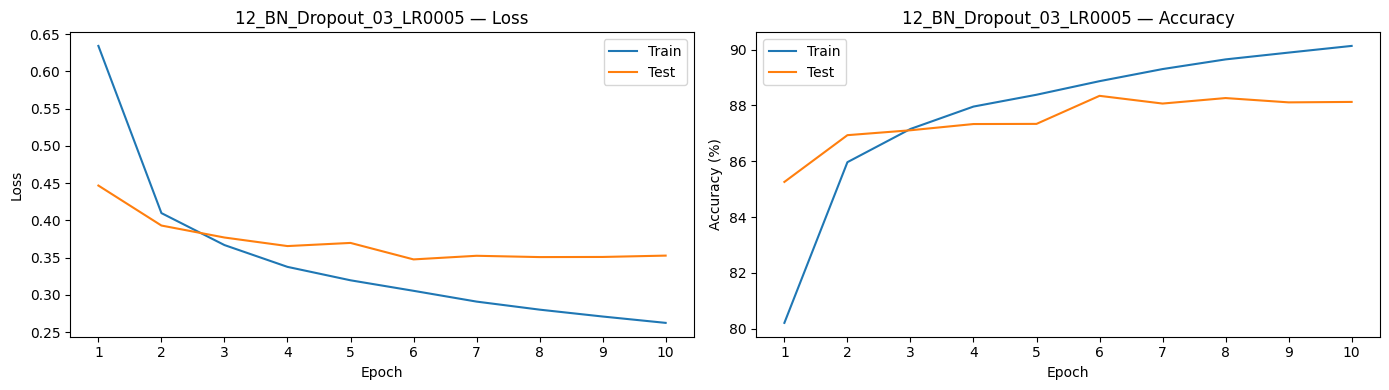

In [17]:
result_12 = run_experiment("12_BN_Dropout_03_LR0005", ThreeLayerCNN_BN_Dropout(len(classes), dropout=0.3), epochs=10, lr=0.0005)

## 17. Experiment 13 — Dropout 0.5, fresh 10-epoch run

**What changes:** increase dropout from 0.3 to 0.5. This is a fresh training run, not a continuation of the previous model.

Epoch 01/10 | Train loss: 0.645 | Train acc: 79.50% | Test loss: 0.430 | Test acc: 85.32% | LR: 0.001
Epoch 02/10 | Train loss: 0.435 | Train acc: 85.20% | Test loss: 0.390 | Test acc: 86.49% | LR: 0.001
Epoch 03/10 | Train loss: 0.390 | Train acc: 86.46% | Test loss: 0.357 | Test acc: 87.57% | LR: 0.001
Epoch 04/10 | Train loss: 0.365 | Train acc: 87.02% | Test loss: 0.356 | Test acc: 87.41% | LR: 0.001
Epoch 05/10 | Train loss: 0.346 | Train acc: 87.68% | Test loss: 0.346 | Test acc: 87.99% | LR: 0.001
Epoch 06/10 | Train loss: 0.332 | Train acc: 87.98% | Test loss: 0.339 | Test acc: 88.23% | LR: 0.001
Epoch 07/10 | Train loss: 0.322 | Train acc: 88.29% | Test loss: 0.334 | Test acc: 88.39% | LR: 0.001
Epoch 08/10 | Train loss: 0.312 | Train acc: 88.65% | Test loss: 0.333 | Test acc: 88.34% | LR: 0.001
Epoch 09/10 | Train loss: 0.303 | Train acc: 88.86% | Test loss: 0.336 | Test acc: 88.39% | LR: 0.001
Epoch 10/10 | Train loss: 0.296 | Train acc: 89.05% | Test loss: 0.328 | Test acc:

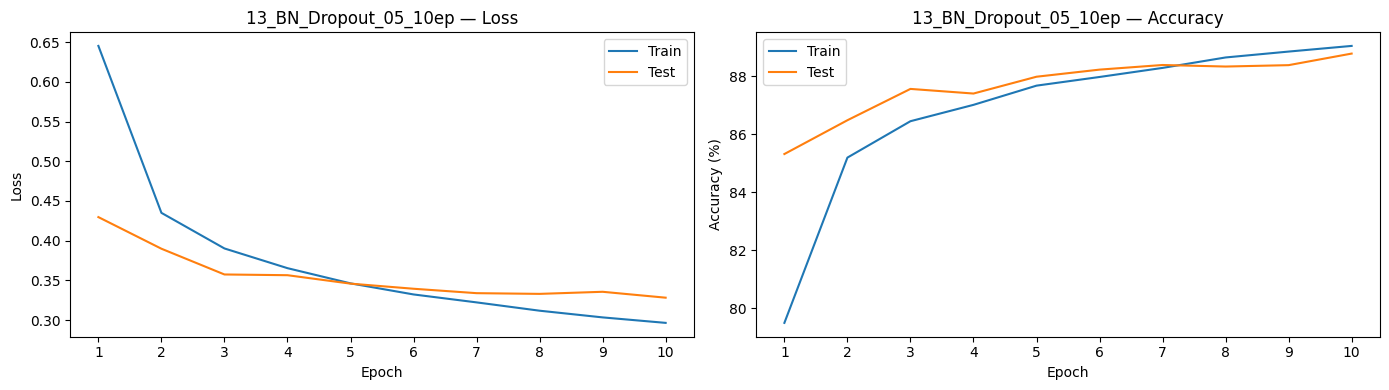

In [18]:
result_13 = run_experiment("13_BN_Dropout_05_10ep", ThreeLayerCNN_BN_Dropout(len(classes), dropout=0.5), epochs=10, lr=0.001)

## 18. Experiment 14 — Dropout 0.5, fresh 20-epoch run

**What changes:** same architecture and learning rate as Experiment 13, but train for 20 epochs instead of 10. The weights are initialized from scratch.

Epoch 01/20 | Train loss: 0.641 | Train acc: 79.76% | Test loss: 0.441 | Test acc: 85.77% | LR: 0.001
Epoch 02/20 | Train loss: 0.437 | Train acc: 85.19% | Test loss: 0.392 | Test acc: 86.71% | LR: 0.001
Epoch 03/20 | Train loss: 0.392 | Train acc: 86.26% | Test loss: 0.372 | Test acc: 86.96% | LR: 0.001
Epoch 04/20 | Train loss: 0.369 | Train acc: 86.85% | Test loss: 0.361 | Test acc: 87.52% | LR: 0.001
Epoch 05/20 | Train loss: 0.350 | Train acc: 87.51% | Test loss: 0.348 | Test acc: 87.72% | LR: 0.001
Epoch 06/20 | Train loss: 0.336 | Train acc: 87.86% | Test loss: 0.345 | Test acc: 88.21% | LR: 0.001
Epoch 07/20 | Train loss: 0.325 | Train acc: 88.18% | Test loss: 0.343 | Test acc: 87.75% | LR: 0.001
Epoch 08/20 | Train loss: 0.315 | Train acc: 88.57% | Test loss: 0.342 | Test acc: 88.40% | LR: 0.001
Epoch 09/20 | Train loss: 0.306 | Train acc: 88.83% | Test loss: 0.331 | Test acc: 88.46% | LR: 0.001
Epoch 10/20 | Train loss: 0.299 | Train acc: 89.00% | Test loss: 0.334 | Test acc:

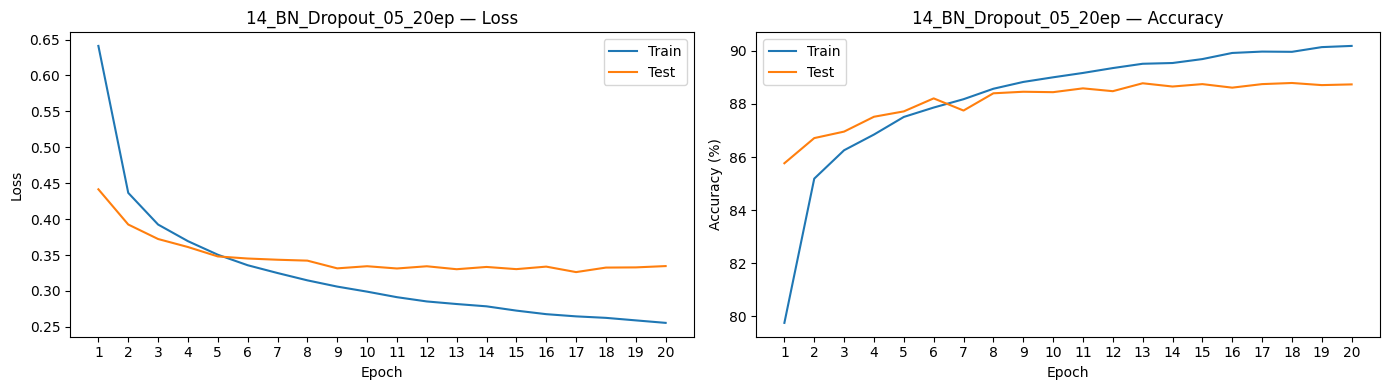

In [19]:
result_14 = run_experiment("14_BN_Dropout_05_20ep", ThreeLayerCNN_BN_Dropout(len(classes), dropout=0.5), epochs=20, lr=0.001)

## 19. Experiment 15 — Increase the final convolution to 64 channels

**What changes:** change the last convolution's output from 32 to 64 channels (16→32→64). Keep Batch Normalization and Dropout(0.5). This tests whether extra capacity improves generalization.

Epoch 01/20 | Train loss: 0.633 | Train acc: 80.20% | Test loss: 0.423 | Test acc: 86.02% | LR: 0.001
Epoch 02/20 | Train loss: 0.413 | Train acc: 85.95% | Test loss: 0.381 | Test acc: 87.03% | LR: 0.001
Epoch 03/20 | Train loss: 0.368 | Train acc: 86.96% | Test loss: 0.359 | Test acc: 87.82% | LR: 0.001
Epoch 04/20 | Train loss: 0.338 | Train acc: 87.96% | Test loss: 0.356 | Test acc: 87.86% | LR: 0.001
Epoch 05/20 | Train loss: 0.316 | Train acc: 88.51% | Test loss: 0.340 | Test acc: 88.15% | LR: 0.001
Epoch 06/20 | Train loss: 0.302 | Train acc: 88.96% | Test loss: 0.342 | Test acc: 88.23% | LR: 0.001
Epoch 07/20 | Train loss: 0.287 | Train acc: 89.37% | Test loss: 0.334 | Test acc: 88.35% | LR: 0.001
Epoch 08/20 | Train loss: 0.274 | Train acc: 89.73% | Test loss: 0.337 | Test acc: 88.28% | LR: 0.001
Epoch 09/20 | Train loss: 0.263 | Train acc: 90.09% | Test loss: 0.340 | Test acc: 88.34% | LR: 0.001
Epoch 10/20 | Train loss: 0.255 | Train acc: 90.30% | Test loss: 0.334 | Test acc:

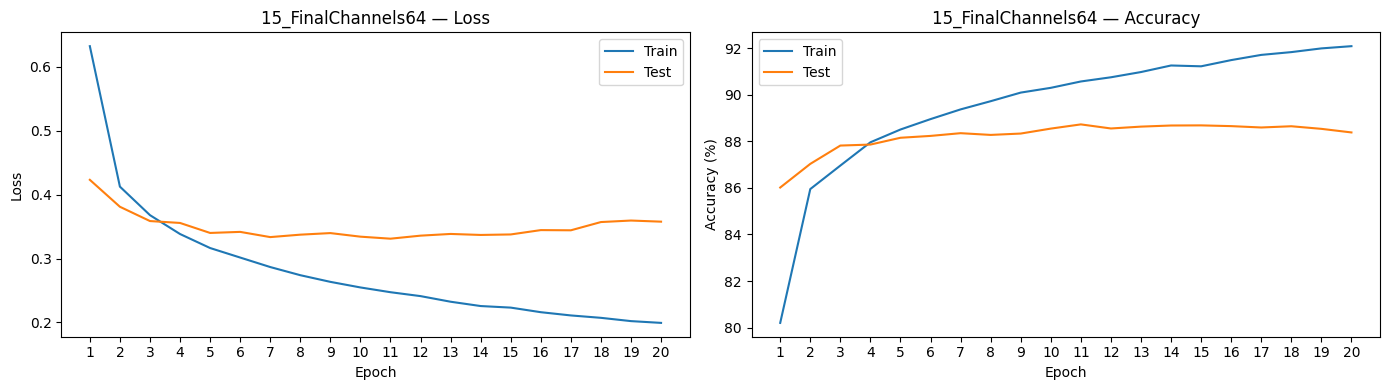

In [20]:
result_15 = run_experiment("15_FinalChannels64", ThreeLayerCNN_BN_Dropout(len(classes), dropout=0.5, final_channels=64), epochs=20, lr=0.001)

## 20. Experiment 16 — Strong data augmentation

**What changes:** keep the 32-channel final model and Dropout(0.5), but train with stronger random affine transformations: ±10° rotation, translation up to 10%, and scale 0.9–1.1. Test images remain unaugmented.

Epoch 01/20 | Train loss: 0.977 | Train acc: 70.29% | Test loss: 0.436 | Test acc: 85.16% | LR: 0.001
Epoch 02/20 | Train loss: 0.643 | Train acc: 79.08% | Test loss: 0.405 | Test acc: 86.05% | LR: 0.001
Epoch 03/20 | Train loss: 0.575 | Train acc: 80.93% | Test loss: 0.397 | Test acc: 86.15% | LR: 0.001
Epoch 04/20 | Train loss: 0.541 | Train acc: 81.96% | Test loss: 0.367 | Test acc: 87.33% | LR: 0.001
Epoch 05/20 | Train loss: 0.518 | Train acc: 82.64% | Test loss: 0.365 | Test acc: 87.36% | LR: 0.001
Epoch 06/20 | Train loss: 0.498 | Train acc: 83.07% | Test loss: 0.355 | Test acc: 87.76% | LR: 0.001
Epoch 07/20 | Train loss: 0.485 | Train acc: 83.42% | Test loss: 0.350 | Test acc: 87.65% | LR: 0.001
Epoch 08/20 | Train loss: 0.476 | Train acc: 83.75% | Test loss: 0.347 | Test acc: 88.01% | LR: 0.001
Epoch 09/20 | Train loss: 0.465 | Train acc: 83.91% | Test loss: 0.347 | Test acc: 87.88% | LR: 0.001
Epoch 10/20 | Train loss: 0.458 | Train acc: 84.15% | Test loss: 0.338 | Test acc:

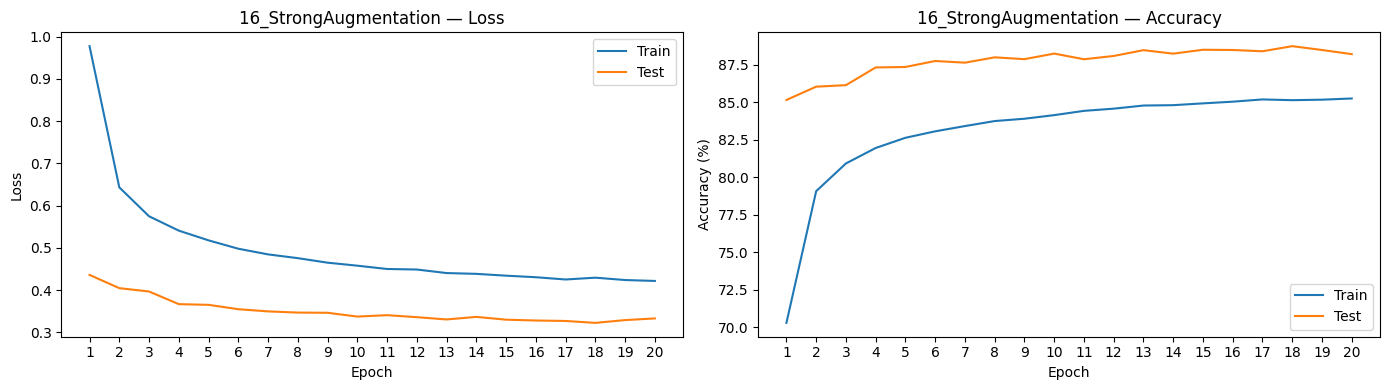

In [21]:
train_dataset, test_dataset, train_loader, test_loader = make_loaders(transform_strong_train)
result_16 = run_experiment("16_StrongAugmentation", ThreeLayerCNN_BN_Dropout(len(classes), dropout=0.5), epochs=20, lr=0.001)

## 21. Experiment 17 — Mild data augmentation

**What changes:** replace the strong transformations with mild ones: ±5° rotation, translation up to 5%, and scale 0.95–1.05. All other settings remain the same.

Epoch 01/20 | Train loss: 0.736 | Train acc: 76.85% | Test loss: 0.423 | Test acc: 85.66% | LR: 0.001
Epoch 02/20 | Train loss: 0.500 | Train acc: 83.21% | Test loss: 0.388 | Test acc: 86.76% | LR: 0.001
Epoch 03/20 | Train loss: 0.452 | Train acc: 84.56% | Test loss: 0.377 | Test acc: 86.93% | LR: 0.001
Epoch 04/20 | Train loss: 0.426 | Train acc: 85.17% | Test loss: 0.360 | Test acc: 87.66% | LR: 0.001
Epoch 05/20 | Train loss: 0.408 | Train acc: 85.68% | Test loss: 0.350 | Test acc: 87.57% | LR: 0.001
Epoch 06/20 | Train loss: 0.395 | Train acc: 86.08% | Test loss: 0.346 | Test acc: 87.90% | LR: 0.001
Epoch 07/20 | Train loss: 0.386 | Train acc: 86.24% | Test loss: 0.335 | Test acc: 88.15% | LR: 0.001
Epoch 08/20 | Train loss: 0.377 | Train acc: 86.59% | Test loss: 0.331 | Test acc: 88.67% | LR: 0.001
Epoch 09/20 | Train loss: 0.369 | Train acc: 86.83% | Test loss: 0.330 | Test acc: 88.52% | LR: 0.001
Epoch 10/20 | Train loss: 0.362 | Train acc: 87.03% | Test loss: 0.322 | Test acc:

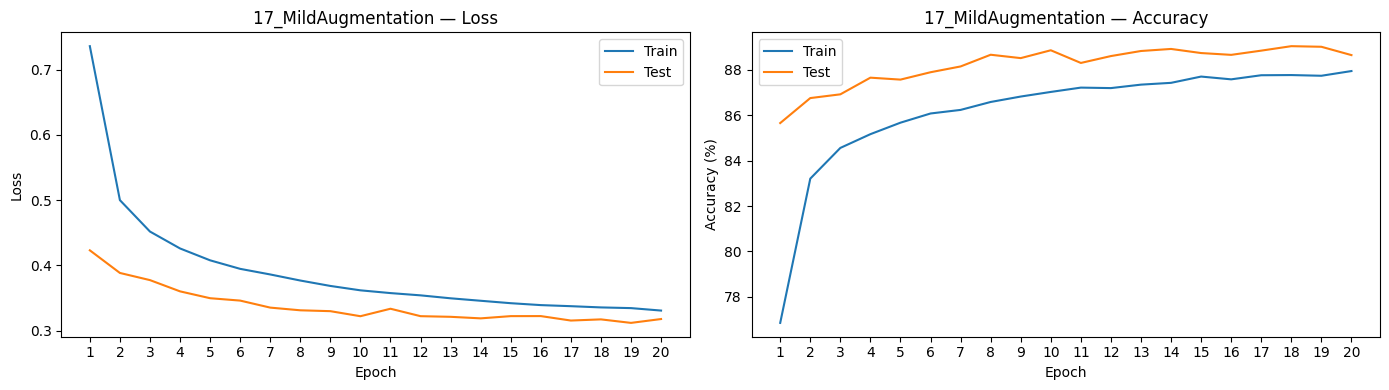

In [22]:
train_dataset, test_dataset, train_loader, test_loader = make_loaders(transform_mild_train)
result_17 = run_experiment("17_MildAugmentation", ThreeLayerCNN_BN_Dropout(len(classes), dropout=0.5), epochs=20, lr=0.001)

## 22. Experiment 18 — Mild augmentation + ReduceLROnPlateau

**What changes:** keep mild augmentation and the same architecture. Add `ReduceLROnPlateau`, which reduces the learning rate by a factor of 0.5 after the test loss stops improving for two epochs. The scheduler may not activate if loss continues improving.

Epoch 01/20 | Train loss: 0.735 | Train acc: 76.96% | Test loss: 0.426 | Test acc: 85.57% | LR: 0.001
Epoch 02/20 | Train loss: 0.496 | Train acc: 83.29% | Test loss: 0.391 | Test acc: 86.37% | LR: 0.001
Epoch 03/20 | Train loss: 0.451 | Train acc: 84.46% | Test loss: 0.374 | Test acc: 87.06% | LR: 0.001
Epoch 04/20 | Train loss: 0.424 | Train acc: 85.26% | Test loss: 0.351 | Test acc: 87.81% | LR: 0.001
Epoch 05/20 | Train loss: 0.406 | Train acc: 85.72% | Test loss: 0.345 | Test acc: 88.05% | LR: 0.001
Epoch 06/20 | Train loss: 0.395 | Train acc: 86.03% | Test loss: 0.339 | Test acc: 88.10% | LR: 0.001
Epoch 07/20 | Train loss: 0.385 | Train acc: 86.28% | Test loss: 0.335 | Test acc: 88.31% | LR: 0.001
Epoch 08/20 | Train loss: 0.372 | Train acc: 86.75% | Test loss: 0.327 | Test acc: 88.31% | LR: 0.001
Epoch 09/20 | Train loss: 0.367 | Train acc: 86.94% | Test loss: 0.333 | Test acc: 88.23% | LR: 0.001
Epoch 10/20 | Train loss: 0.362 | Train acc: 86.98% | Test loss: 0.332 | Test acc:

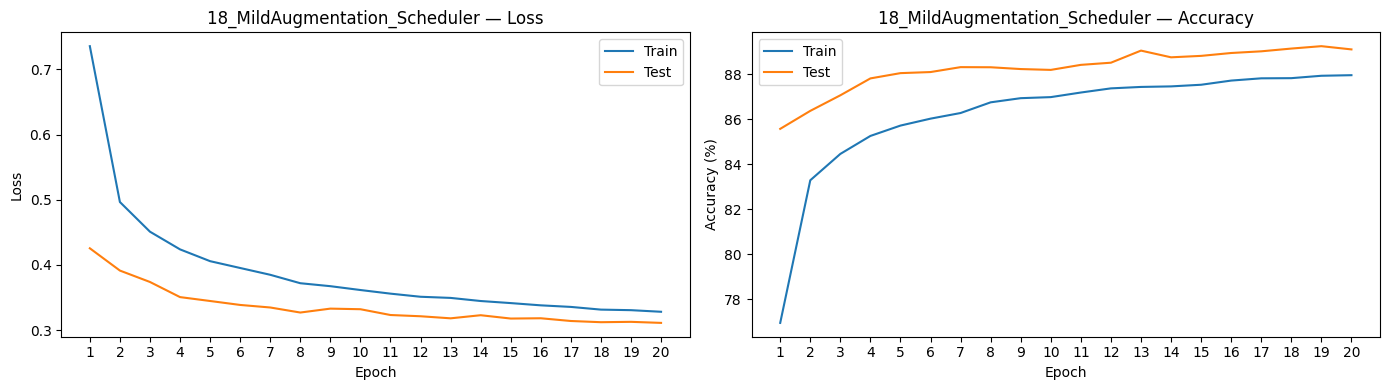

In [23]:
result_18 = run_experiment(
    "18_MildAugmentation_Scheduler",
    ThreeLayerCNN_BN_Dropout(len(classes), dropout=0.5),
    epochs=20,
    lr=0.001,
    scheduler_type="plateau",
    scheduler_patience=2,
    scheduler_factor=0.5
)

## 23. Experiment 19 — Global Average Pooling (GAP)

**What changes:** replace flattening of the 32×9×9 feature map with `AdaptiveAvgPool2d(1)`, reducing it to 32 values before the classifier. This sharply reduces classifier parameters, but may discard useful spatial detail for character recognition.

Epoch 01/20 | Train loss: 2.603 | Train acc: 28.02% | Test loss: 1.437 | Test acc: 69.11% | LR: 0.001
Epoch 02/20 | Train loss: 1.881 | Train acc: 43.85% | Test loss: 1.068 | Test acc: 74.06% | LR: 0.001
Epoch 03/20 | Train loss: 1.697 | Train acc: 48.60% | Test loss: 0.933 | Test acc: 76.21% | LR: 0.001
Epoch 04/20 | Train loss: 1.586 | Train acc: 51.28% | Test loss: 0.819 | Test acc: 78.34% | LR: 0.001
Epoch 05/20 | Train loss: 1.507 | Train acc: 53.76% | Test loss: 0.793 | Test acc: 79.23% | LR: 0.001
Epoch 06/20 | Train loss: 1.450 | Train acc: 55.37% | Test loss: 0.742 | Test acc: 80.12% | LR: 0.001
Epoch 07/20 | Train loss: 1.403 | Train acc: 56.76% | Test loss: 0.702 | Test acc: 80.23% | LR: 0.001
Epoch 08/20 | Train loss: 1.367 | Train acc: 57.66% | Test loss: 0.686 | Test acc: 80.64% | LR: 0.001
Epoch 09/20 | Train loss: 1.336 | Train acc: 58.27% | Test loss: 0.673 | Test acc: 80.88% | LR: 0.001
Epoch 10/20 | Train loss: 1.308 | Train acc: 59.28% | Test loss: 0.646 | Test acc:

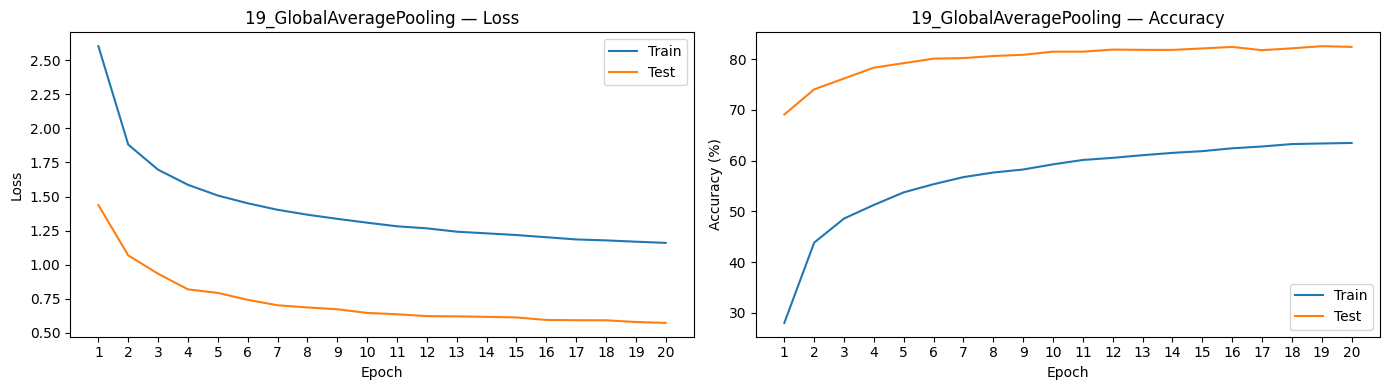

In [24]:
class ThreeLayerCNN_GAP(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, 3),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, 3),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

result_19 = run_experiment(
    "19_GlobalAveragePooling",
    ThreeLayerCNN_GAP(len(classes)),
    epochs=20,
    lr=0.001,
    scheduler_type="plateau",
    scheduler_patience=2,
    scheduler_factor=0.5
)

## 24. Experiment 20 — CNN_BlockModel (best observed model)

**What changes:** reorganize the network into two convolutional blocks. Block 1 has two 32-channel convolutions followed by pooling; Block 2 has two 64-channel convolutions followed by pooling. This allows two feature-extraction steps at each resolution before downsampling. The classifier receives a 64×7×7 feature map.

This was the best observed run: **89.85% test accuracy at epoch 19**, test loss 0.289. Re-running may produce a different result.

Epoch 01/20 | Train loss: 0.720 | Train acc: 77.35% | Test loss: 0.406 | Test acc: 86.36% | LR: 0.001
Epoch 02/20 | Train loss: 0.463 | Train acc: 84.22% | Test loss: 0.376 | Test acc: 86.93% | LR: 0.001
Epoch 03/20 | Train loss: 0.413 | Train acc: 85.63% | Test loss: 0.347 | Test acc: 87.93% | LR: 0.001
Epoch 04/20 | Train loss: 0.389 | Train acc: 86.35% | Test loss: 0.328 | Test acc: 88.82% | LR: 0.001
Epoch 05/20 | Train loss: 0.370 | Train acc: 86.81% | Test loss: 0.328 | Test acc: 88.27% | LR: 0.001
Epoch 06/20 | Train loss: 0.356 | Train acc: 87.25% | Test loss: 0.321 | Test acc: 88.81% | LR: 0.001
Epoch 07/20 | Train loss: 0.347 | Train acc: 87.55% | Test loss: 0.312 | Test acc: 89.01% | LR: 0.001
Epoch 08/20 | Train loss: 0.336 | Train acc: 87.86% | Test loss: 0.307 | Test acc: 89.19% | LR: 0.001
Epoch 09/20 | Train loss: 0.329 | Train acc: 88.09% | Test loss: 0.305 | Test acc: 89.10% | LR: 0.001
Epoch 10/20 | Train loss: 0.324 | Train acc: 88.16% | Test loss: 0.299 | Test acc:

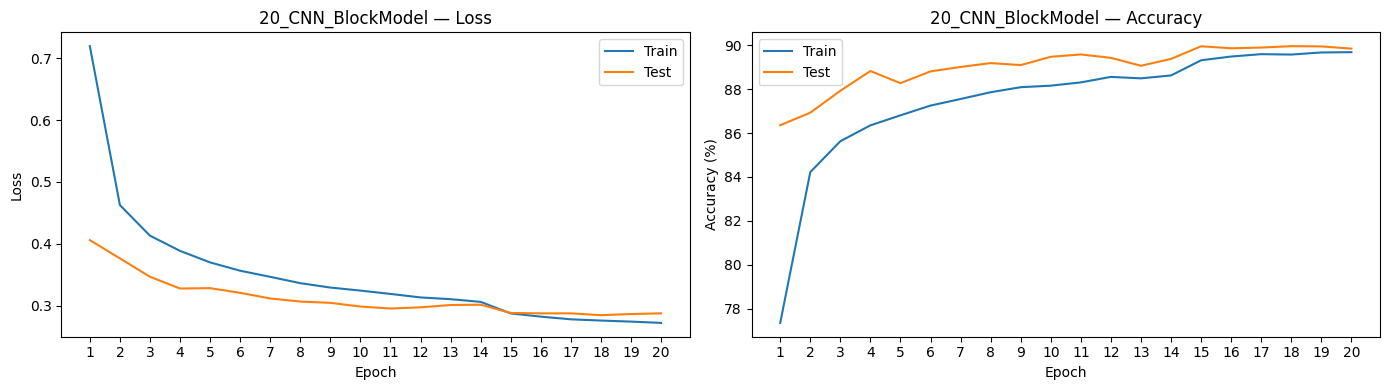

In [25]:
class CNN_BlockModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2, 2),

            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(64 * 7 * 7, num_classes)
        )

    def forward(self, x):
        return self.network(x)

result_20 = run_experiment(
    "20_CNN_BlockModel",
    CNN_BlockModel(len(classes)),
    epochs=20,
    lr=0.001,
    scheduler_type="plateau",
    scheduler_patience=2,
    scheduler_factor=0.5
)

## 25. Compare all runs

This table is generated from the experiments you actually ran in this notebook. Sort by best test accuracy to see the current ranking.

In [26]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Experiment": r["experiment"],
        "Epochs": r["epochs"],
        "Learning rate": r["learning_rate"],
        "Best epoch": r["best_epoch"],
        "Best test accuracy (%)": r["best_test_accuracy"],
        "Test loss at best accuracy": r["test_loss_at_best_accuracy"],
        "Final train accuracy (%)": r["final_train_accuracy"],
        "Final test accuracy (%)": r["final_test_accuracy"],
        "Final test loss": r["final_test_loss"],
        "Minutes": r["seconds"] / 60
    }
    for r in experiment_results
]).sort_values("Best test accuracy (%)", ascending=False).reset_index(drop=True)

comparison

,Experiment,Epochs,Learning rate,Best epoch,Best test accuracy (%),Test loss at best accuracy,Final train accuracy (%),Final test accuracy (%),Final test loss,Minutes
0,20_CNN_BlockModel,20,0.0010,18,89.957447,0.284631,89.683511,89.845745,0.287564,13.602747
1,18_MildAugmentation_Scheduler,20,0.0010,19,89.244681,0.312757,87.956560,89.101064,0.311153,14.230407
2,17_MildAugmentation,20,0.0010,18,89.047872,0.317350,87.951241,88.654255,0.317871,14.082788
3,13_BN_Dropout_05_10ep,10,0.0010,10,88.787234,0.328123,89.051418,88.787234,0.328123,4.734960
4,14_BN_Dropout_05_20ep,20,0.0010,18,88.787234,0.332487,90.182624,88.734043,0.334581,9.441481
5,16_StrongAugmentation,20,0.0010,18,88.750000,0.322686,85.260638,88.218085,0.333238,14.021177
6,15_FinalChannels64,20,0.0010,11,88.728723,0.331051,92.089539,88.382979,0.357712,9.934905
7,11_BN_Dropout_03,10,0.0010,9,88.484043,0.346854,90.480496,88.122340,0.351772,4.719650
8,12_BN_Dropout_03_LR0005,10,0.0005,6,88.345745,0.347722,90.134752,88.127660,0.352813,4.722026
9,10_ThreeLayerCNN_BN,10,0.0010,5,87.978723,0.356279,92.842199,87.218085,0.400683,4.582711


## 26. Save the best model from this notebook

This saves the best-performing model state observed during these runs. It does not save the entire notebook or the training curves.

In [27]:
if best_overall["model_state"] is not None:
    torch.save(
        {
            "experiment": best_overall["experiment"],
            "best_test_accuracy": best_overall["accuracy"],
            "model_state_dict": best_overall["model_state"],
            "classes": classes
        },
        "emnist_cnn_best_model.pth"
    )
    print("Saved:", best_overall["experiment"])
    print(f"Best test accuracy: {best_overall['accuracy']:.2f}%")

Saved: 20_CNN_BlockModel
Best test accuracy: 89.96%


## Notes for interpreting the experiment

- Compare **best test accuracy and test loss**, but also inspect the train/test gap and curves.
- A higher training accuracy alone does not mean a better model; the extra 64-channel model did not beat the 32-channel version in the earlier runs.
- Strong augmentation was worse than mild augmentation in the earlier runs. More augmentation is not automatically better.
- GAP performed poorly here because it compresses the 9×9 spatial map to one value per channel. Character identity can depend on where strokes occur.
- The CNN_BlockModel was the strongest model observed so far. Do not claim 89.85% as a guaranteed reproducible result; report the score from your own run.
- For a stronger research-quality evaluation, create a validation split from the training set, use validation metrics for architecture/scheduler/model selection, and reserve the official test set for the final evaluation.